# 03 · Decision Analysis: Who Should Get a Retention Offer?

The model from notebook 02 tells us **how likely** each customer is to churn. That alone doesn't tell the business what to *do*.

**Decision:** for each customer, send a retention offer, or not?

A prediction is only valuable if it leads to a **better decision**. So here we:
1. Put a **dollar value** on every possible outcome
2. Find the targeting rule that **maximises profit**
3. Test how sensitive that decision is to our assumptions

We use the **1,409 test-set customers**, whose churn the model never saw, so the results are an honest estimate.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)

d = pd.read_csv("../data/test_predictions.csv")
p = d["churn_probability"].values      # predicted churn probability
y = d["actual_churn"].values           # what really happened
M = d["MonthlyCharges"].values         # monthly bill ($)
SCALE = 7043 / len(d)                  # test set = 20% of customers -> scale results to the full base
d.head()

,tenure,Contract,InternetService,MonthlyCharges,customerID,churn_probability,actual_churn
0,72,Two year,Fiber optic,114.05,4376-KFVRS,0.05,0
1,8,Month-to-month,Fiber optic,100.15,2754-SDJRD,0.68,0
2,41,One year,DSL,78.35,9917-KWRBE,0.06,0
3,18,Month-to-month,Fiber optic,78.20,0365-GXEZS,0.40,0
4,72,Two year,DSL,82.65,9385-NXKDA,0.02,0


## 1. The business assumptions

The offer: **20% off the monthly bill for 3 months**, plus a $5 cost to contact the customer.

| Assumption | Value | Reasoning |
|---|---|---|
| **Value of keeping a customer** | 12 months × monthly bill × 60% margin | One year of profit we would otherwise lose (a conservative horizon) |
| **Offer cost** | 3 months × 20% × monthly bill + $5 contact | Paid by **everyone** who gets the offer, including customers who would have stayed anyway |
| **Success rate** | 30% | Share of would-be churners who stay *because of* the offer |

These numbers are **assumptions**, not facts, so section 5 tests how the decision changes when they change.

### Profit of sending an offer

| | Customer would have churned | Customer would have stayed |
|---|---|---|
| **Offer sent** | 30% chance we save them (+value) − offer cost | − offer cost (wasted discount) |
| **No offer** | $0 (we lose them, but that is the baseline) | $0 |

So the **expected profit of targeting customer *i*** is:

$$\text{E[profit]}_i = p_i \times \text{success rate} \times \text{value}_i - \text{cost}_i$$

In [2]:
ASSUMPTIONS = dict(success_rate=0.30, discount=0.20, discount_months=3, margin=0.60, horizon_months=12, contact_cost=5.0)

def value_and_cost(M, success_rate, discount, discount_months, margin, horizon_months, contact_cost):
    value = M * horizon_months * margin                     # profit kept if a churner is saved
    cost = M * discount_months * discount + contact_cost    # cost of sending one offer
    return value, cost

V, C = value_and_cost(M, **ASSUMPTIONS)
print(f"Average customer: value if saved = ${V.mean():,.0f}, cost of an offer = ${C.mean():,.0f}")

Average customer: value if saved = $461, cost of an offer = $43


### Break-even probability

Targeting is worth it when expected gain > cost:  $p \times s \times V > C$  →  $p > \dfrac{C}{s \times V}$

For an average customer:

In [3]:
s = ASSUMPTIONS["success_rate"]
breakeven = C.mean() / (s * V.mean())
print(f"Break-even churn probability ≈ {breakeven:.2f}")

Break-even churn probability ≈ 0.31


So the economics say: **target customers whose churn risk is above roughly 30%**. That's very different from the conventional 0.5.
Let's confirm this with the actual test-set outcomes.

## 2. Profit for every possible threshold

For each threshold *t* we target everyone with $p \ge t$ and calculate the profit using **what actually happened**:
real churners contribute `success rate × value − cost`, and customers who stayed contribute `− cost`.

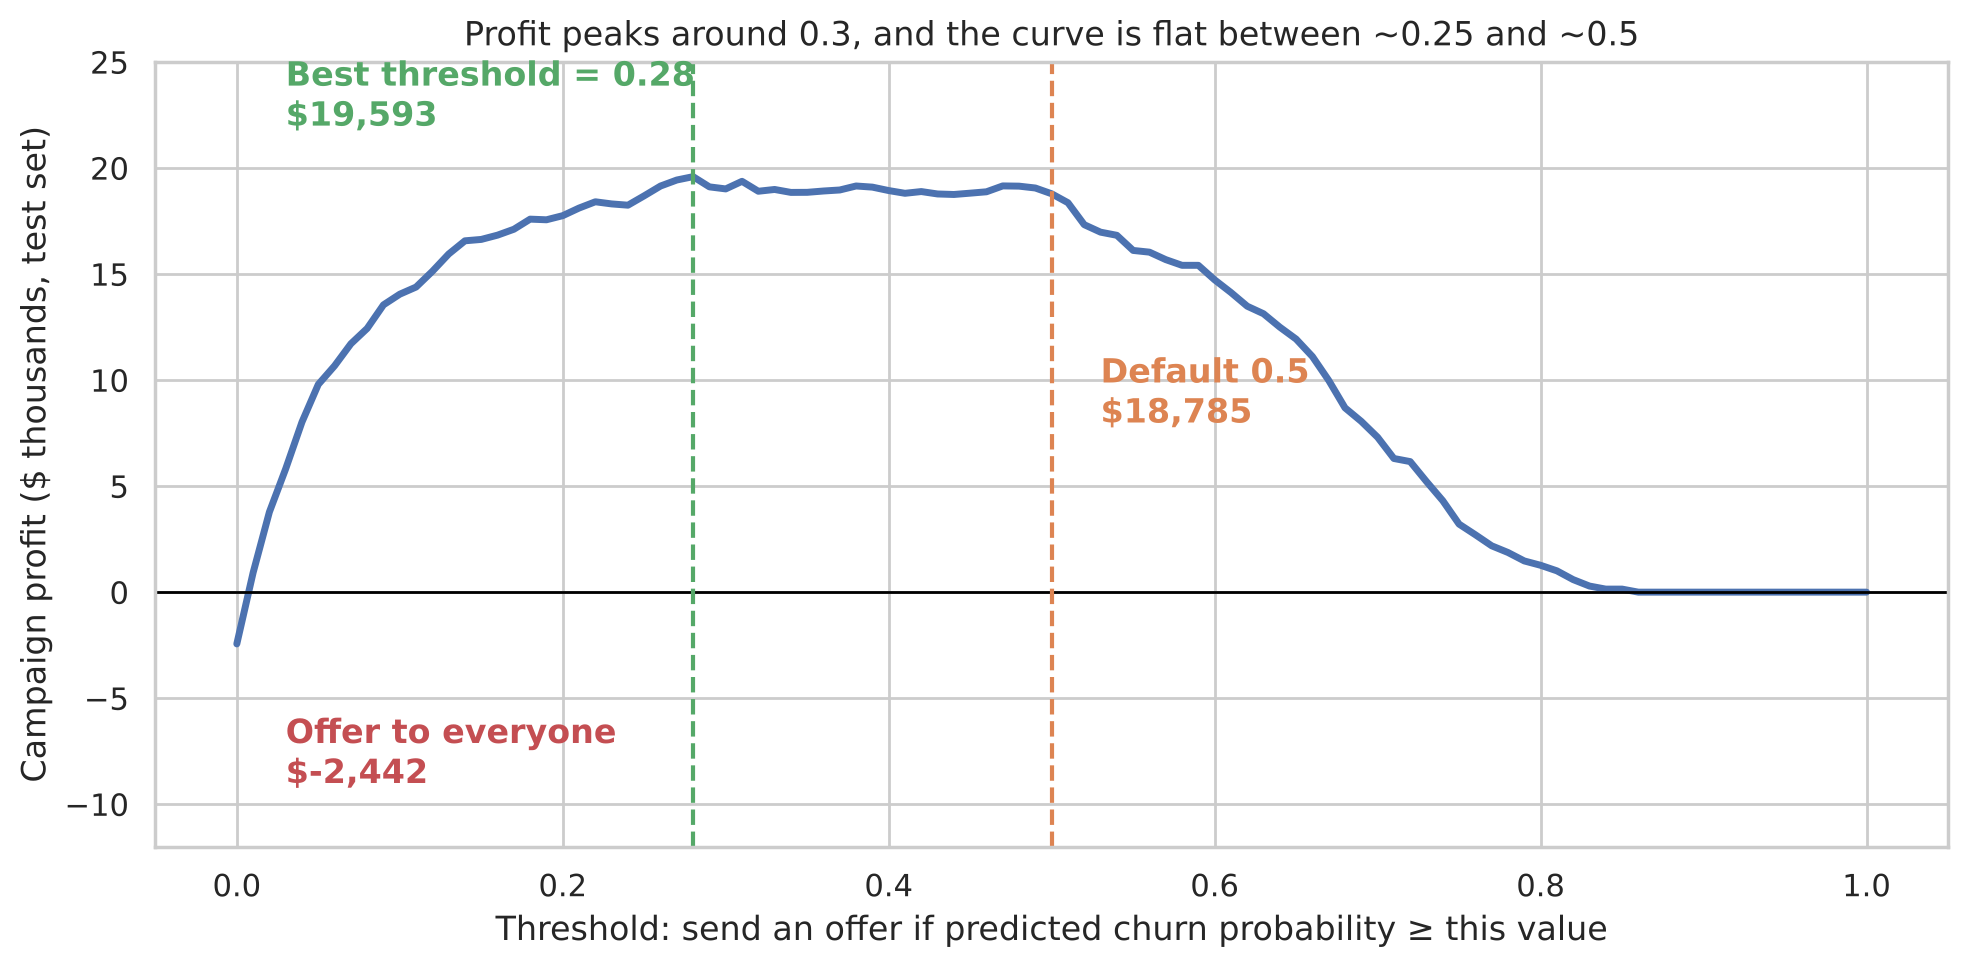

In [4]:
def campaign_profit(targeted, y, V, C, success_rate):
    return (y[targeted] * success_rate * V[targeted]).sum() - C[targeted].sum()

def threshold_curve(p, y, V, C, success_rate):
    thresholds = np.round(np.arange(0, 1.0001, 0.01), 2)
    rows = []
    for t in thresholds:
        tg = p >= t
        rows.append({"threshold": t, "profit": campaign_profit(tg, y, V, C, success_rate),
                     "customers_targeted": tg.sum(), "churners_reached": y[tg].sum()})
    return pd.DataFrame(rows).set_index("threshold")

curve = threshold_curve(p, y, V, C, s)
best_t = curve["profit"].idxmax()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(curve.index, curve["profit"] / 1000, color="#4C72B0", lw=2.5)
ax.axhline(0, color="black", lw=1)
for t, label, c, xy_text in [(best_t, f"Best threshold = {best_t:.2f}", "#55A868", (best_t - 0.25, 22)),
                             (0.5, "Default 0.5", "#DD8452", (0.53, 8))]:
    ax.axvline(t, color=c, ls="--", lw=1.5)
    ax.annotate(f"{label}\n${curve.loc[t, 'profit']:,.0f}", (t, curve.loc[t, "profit"] / 1000),
                xytext=xy_text, color=c, fontweight="bold")
ax.annotate(f"Offer to everyone\n${curve.loc[0.0, 'profit']:,.0f}", (0, curve.loc[0.0, "profit"] / 1000),
            xytext=(0.03, -9), color="#C44E52", fontweight="bold")
ax.set_xlabel("Threshold: send an offer if predicted churn probability ≥ this value")
ax.set_ylabel("Campaign profit ($ thousands, test set)")
ax.set_title("Profit peaks around 0.3, and the curve is flat between ~0.25 and ~0.5")
ax.set_ylim(-12, 25)
plt.tight_layout()
plt.savefig("../reports/figures/03_profit_curve.png", dpi=150)
plt.show()

The data-driven best threshold lands close to the **~0.30 break-even** we derived on paper, a good consistency check.

Notice the curve is **fairly flat between ~0.25 and ~0.5**. With these assumptions, the exact threshold matters less than you might think.
What matters most is **targeting at all instead of everyone**: offering to all customers *loses* money, because most of them would have stayed anyway.

## 3. Comparing strategies

In [5]:
ev = p * s * V - C   # individual expected profit: target only where it is positive
strategies = {
    "Do nothing": np.zeros_like(p, dtype=bool),
    "Offer to everyone": np.ones_like(p, dtype=bool),
    "Model, default threshold 0.5": p >= 0.5,
    f"Model, profit-optimal threshold {best_t:.2f}": p >= best_t,
    "Model, individual expected-value rule": ev > 0,
    "Perfect foresight (only real churners)": y == 1,
}
rows = []
for name, tg in strategies.items():
    rows.append({"Strategy": name,
                 "Customers targeted": tg.sum(),
                 "Churners reached": y[tg].sum(),
                 "Offers wasted on stayers": (tg & (y == 0)).sum(),
                 "Campaign cost": C[tg].sum(),
                 "Profit (test set)": campaign_profit(tg, y, V, C, s)})
comp = pd.DataFrame(rows).set_index("Strategy")
comp["Profit (scaled to all 7,043 customers)"] = comp["Profit (test set)"] * SCALE
comp

,Customers targeted,Churners reached,Offers wasted on stayers,Campaign cost,Profit (test set),"Profit (scaled to all 7,043 customers)"
Strategy,,,,,,
Do nothing,0,0,0,0.00,0.00,0.00
Offer to everyone,1409,374,1035,"61,225.72","-2,441.54","-12,204.21"
"Model, default threshold 0.5",318,209,109,"16,716.99","18,785.42","93,900.43"
"Model, profit-optimal threshold 0.28",563,291,272,"28,608.10","19,592.52","97,934.77"
"Model, individual expected-value rule",524,278,246,"27,111.40","19,216.50","96,055.20"
Perfect foresight (only real churners),374,374,0,"18,198.94","40,585.24","202,868.61"


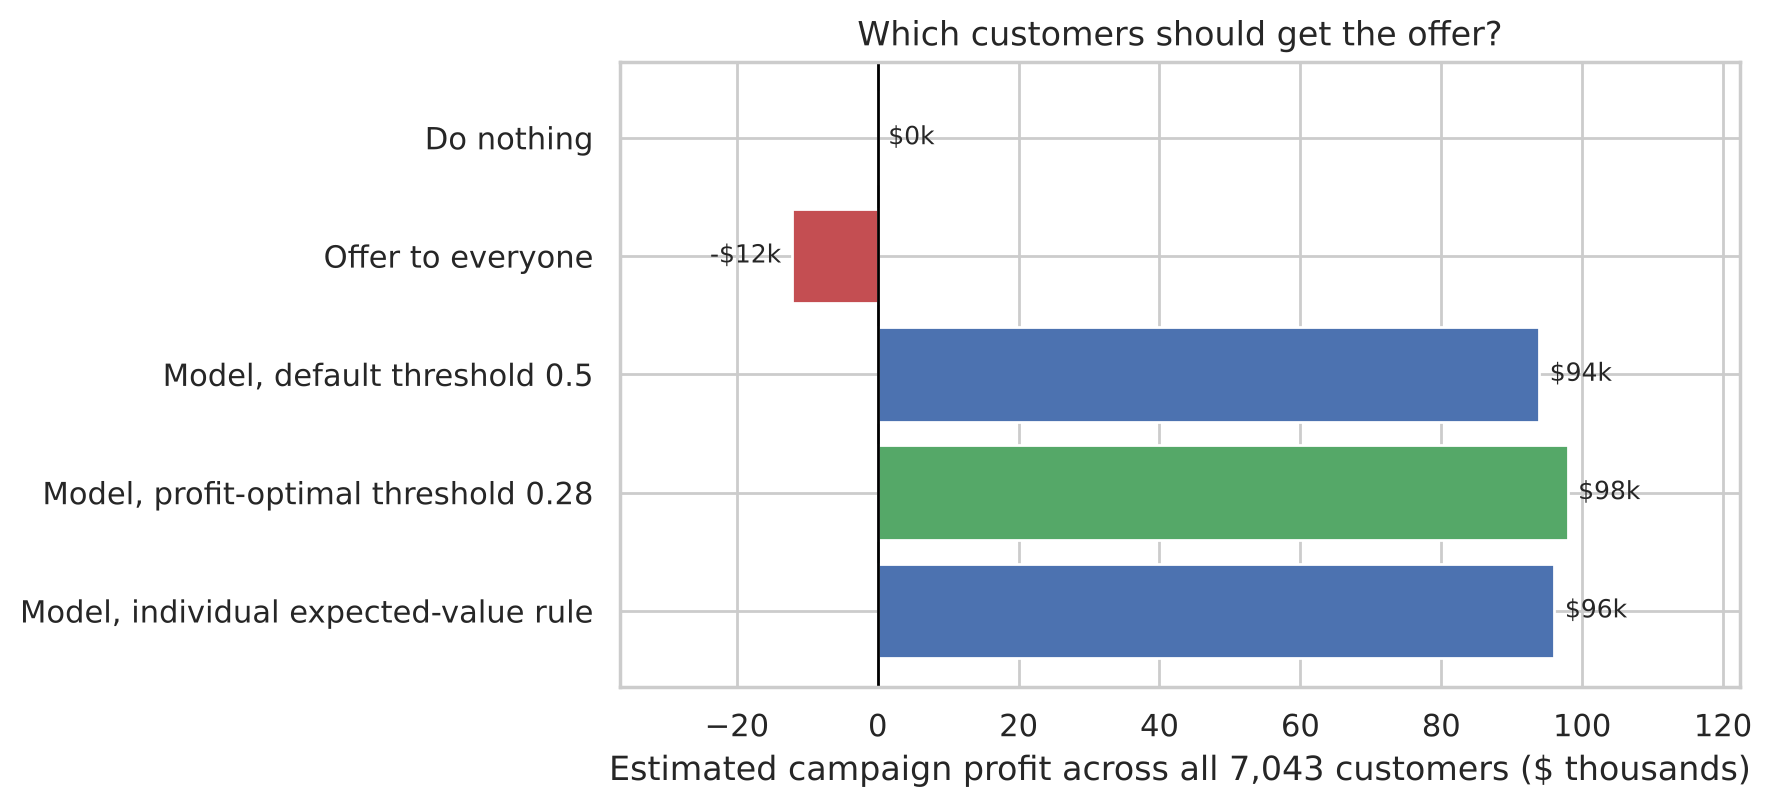

In [6]:
plot = comp["Profit (scaled to all 7,043 customers)"].drop("Perfect foresight (only real churners)") / 1000
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = ["#C44E52" if v < 0 else ("#55A868" if v == plot.max() else "#4C72B0") for v in plot.values]
ax.barh(plot.index, plot.values, color=colors)
ax.axvline(0, color="black", lw=1)
for i, v in enumerate(plot.values):
    ax.text(v + (1.5 if v >= 0 else -1.5), i, f"{'-' if v < 0 else ''}${abs(v):,.0f}k", va="center", ha="left" if v >= 0 else "right", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(plot.min() * 3 if plot.min() < 0 else 0, plot.max() * 1.25)
ax.set_xlabel("Estimated campaign profit across all 7,043 customers ($ thousands)")
ax.set_title("Which customers should get the offer?")
plt.tight_layout()
plt.savefig("../reports/figures/03_strategies.png", dpi=150)
plt.show()

In [7]:
best = comp.loc[f"Model, profit-optimal threshold {best_t:.2f}"]
perfect = comp.loc["Perfect foresight (only real churners)"]
print(f"Optimal targeting contacts {best['Customers targeted'] / len(d):.0%} of customers "
      f"and reaches {best['Churners reached'] / y.sum():.0%} of churners.")
print(f"It captures {best['Profit (test set)'] / perfect['Profit (test set)']:.0%} of the profit a perfect, all-knowing model would make.")

Optimal targeting contacts 40% of customers and reaches 78% of churners.
It captures 48% of the profit a perfect, all-knowing model would make.


**The individual expected-value rule** (target where $p_i \times s \times V_i > C_i$) performs about as well as the best single threshold.
It has one practical advantage: it needs **no tuning on past outcomes**. It follows directly from the economics and adapts to each customer's bill.

## 4. Who gets the offer?

In [8]:
d["targeted"] = d["churn_probability"] >= best_t
summary = d.groupby("targeted").agg(customers=("customerID", "size"), avg_probability=("churn_probability", "mean"),
                                    actual_churn_rate=("actual_churn", "mean"), median_tenure=("tenure", "median"),
                                    avg_monthly_bill=("MonthlyCharges", "mean"))
summary.index = ["Not targeted", "Targeted"]
summary

,customers,avg_probability,actual_churn_rate,median_tenure,avg_monthly_bill
Not targeted,846,0.09,0.10,48.00,55.93
Targeted,563,0.54,0.52,10.00,76.36


In [9]:
pd.crosstab(d["targeted"].map({True: "Targeted", False: "Not targeted"}), d["Contract"], normalize="index").mul(100).round(0)

Contract,Month-to-month,One year,Two year
targeted,,,
Not targeted,28.00,33.00,40.00
Targeted,96.00,4.00,0.00


Targeted customers are overwhelmingly **month-to-month, early-tenure** customers, the same risk group the EDA found.
That's reassuring: the model's decisions are consistent with business intuition.

## 5. Sensitivity analysis: what if our assumptions are wrong?

The two most uncertain assumptions are **how often the offer works** and **how big the discount is**.
For every combination we find the best threshold again and compare its profit with the default 0.5 rule.

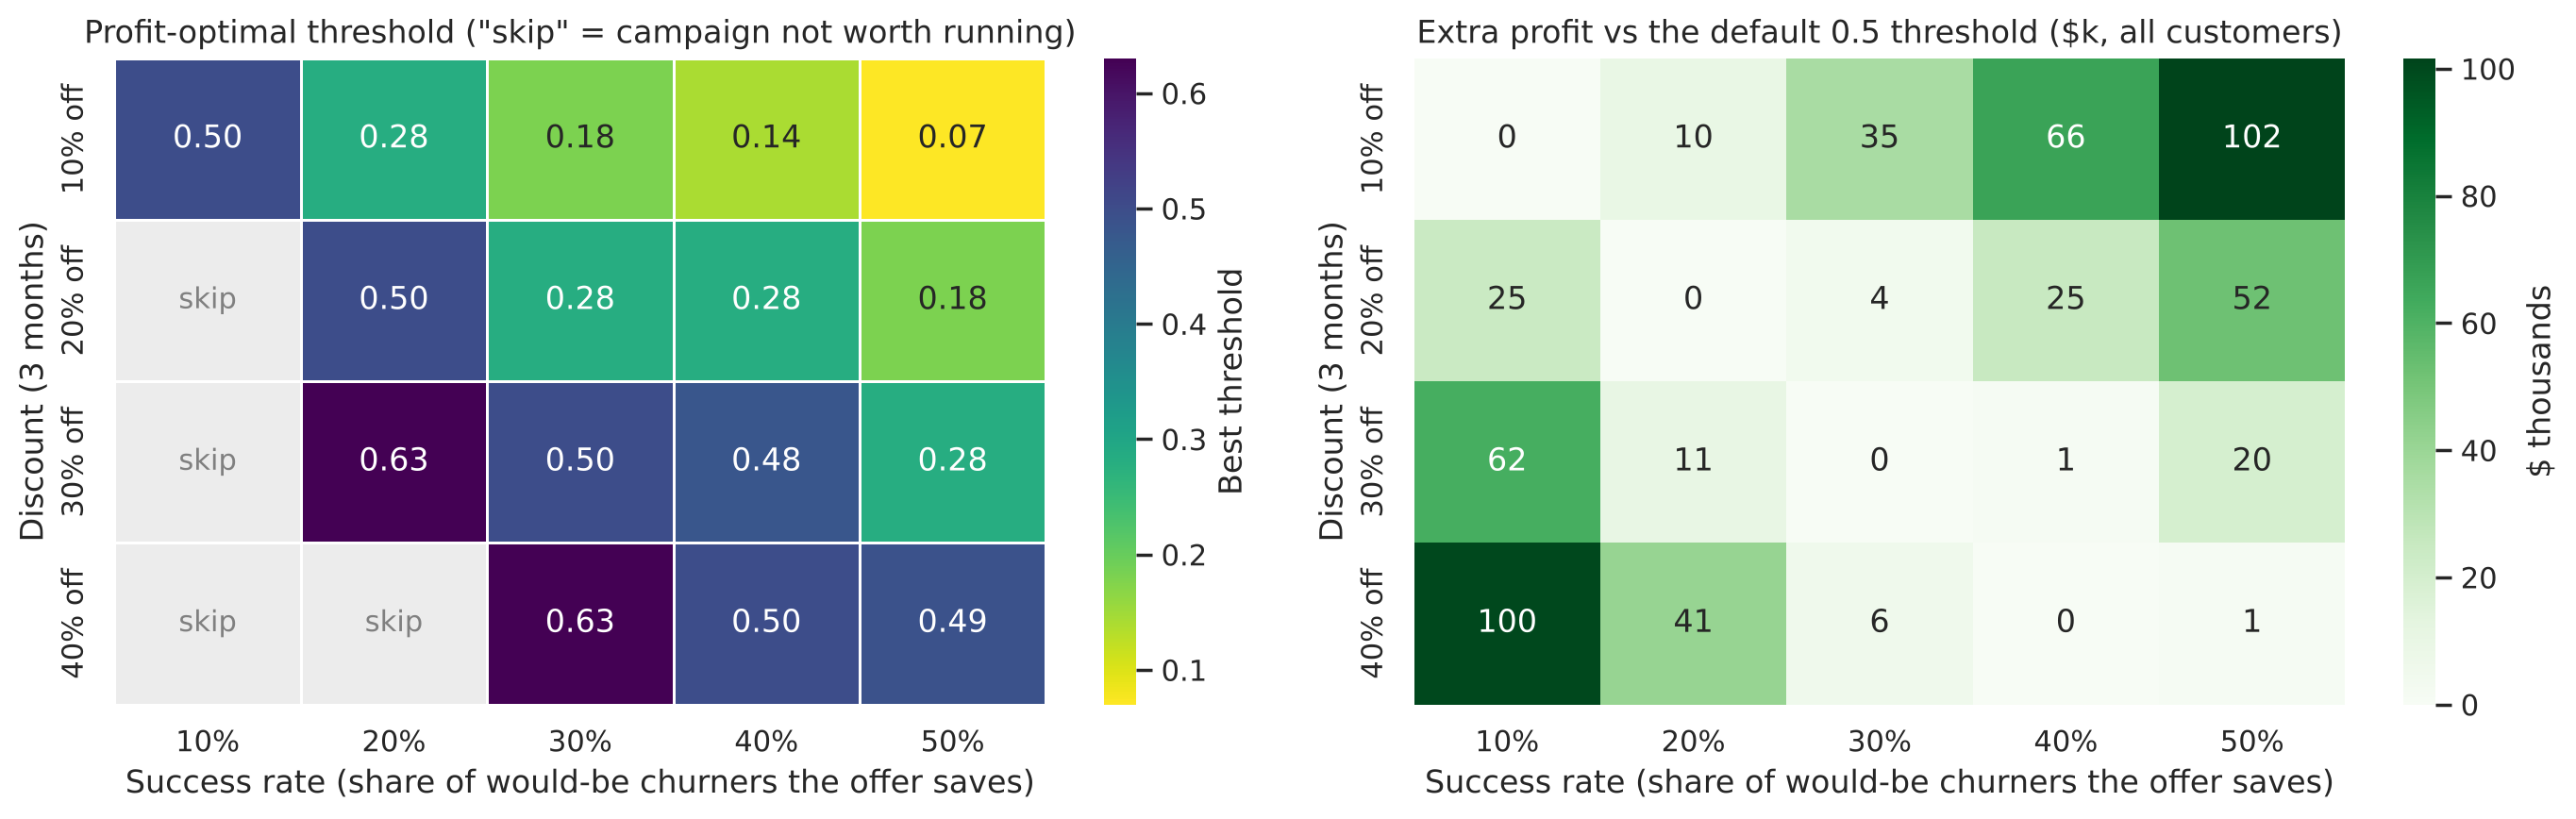

In [10]:
success_rates = [0.10, 0.20, 0.30, 0.40, 0.50]
discounts = [0.10, 0.20, 0.30, 0.40]
best_thr = pd.DataFrame(index=[f"{d_:.0%} off" for d_ in discounts], columns=[f"{s_:.0%}" for s_ in success_rates], dtype=float)
best_profit = best_thr.copy(); profit_05 = best_thr.copy(); profit_all = best_thr.copy()

for disc in discounts:
    for sr in success_rates:
        a = {**ASSUMPTIONS, "discount": disc, "success_rate": sr}
        V_, C_ = value_and_cost(M, **a)
        cv_ = threshold_curve(p, y, V_, C_, sr)
        r, c = f"{disc:.0%} off", f"{sr:.0%}"
        best_thr.loc[r, c] = cv_["profit"].idxmax()
        best_profit.loc[r, c] = cv_["profit"].max() * SCALE / 1000
        profit_05.loc[r, c] = cv_.loc[0.5, "profit"] * SCALE / 1000
        profit_all.loc[r, c] = cv_.loc[0.0, "profit"] * SCALE / 1000

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
# where even the best threshold makes (almost) no profit, the real answer is "don't run the campaign"
skip = best_profit < 1
labels = best_thr.map(lambda v: f"{v:.2f}").where(~skip, "skip")
sns.heatmap(best_thr.mask(skip), annot=labels, fmt="", cmap="viridis_r", ax=axes[0], cbar_kws={"label": "Best threshold"},
            linewidths=0.5, linecolor="white")
axes[0].grid(False); axes[0].set_facecolor("#ececec")
for i in range(skip.shape[0]):          # masked cells don't show annotations, so write "skip" ourselves
    for j in range(skip.shape[1]):
        if skip.iloc[i, j]:
            axes[0].text(j + 0.5, i + 0.5, "skip", ha="center", va="center", color="grey", fontsize=11)
axes[0].set_title('Profit-optimal threshold ("skip" = campaign not worth running)')
gain = best_profit - profit_05
sns.heatmap(gain, annot=True, fmt=",.0f", cmap="Greens", ax=axes[1], cbar_kws={"label": "$ thousands"})
axes[1].set_title("Extra profit vs the default 0.5 threshold ($k, all customers)")
for ax in axes:
    ax.set_xlabel("Success rate (share of would-be churners the offer saves)"); ax.set_ylabel("Discount (3 months)")
plt.tight_layout()
plt.savefig("../reports/figures/03_sensitivity.png", dpi=150)
plt.show()

In [11]:
print("Profit at the best threshold ($k, all customers):")
display(best_profit.round(0))
print("Profit if we offer to EVERYONE ($k):")
display(profit_all.round(0))

Profit at the best threshold ($k, all customers):


,10%,20%,30%,40%,50%
10% off,13.00,82.00,167.00,257.00,352.00
20% off,0.00,35.00,98.00,178.00,264.00
30% off,0.00,8.00,56.00,117.00,194.00
40% off,0.00,0.00,24.00,77.00,138.00


Profit if we offer to EVERYONE ($k):


,10%,20%,30%,40%,50%
10% off,-73.00,25.00,123.00,221.00,319.00
20% off,-208.00,-110.00,-12.00,86.00,184.00
30% off,-344.00,-246.00,-148.00,-50.00,48.00
40% off,-479.00,-381.00,-283.00,-185.00,-87.00


### What the sensitivity analysis tells the business

1. **The best threshold is not fixed. It moves with the economics.**
   - A cheap offer that works well → target broadly (threshold ~0.1–0.2).
   - An expensive offer that rarely works → target only the very riskiest (threshold ≥ 0.5), or **don't run the campaign at all** ("skip").
2. **The default 0.5 is only right by coincidence**, in a narrow band of assumptions. When offers work well, it leaves a lot of money on the table.
3. **Offering to everyone is only profitable when the offer is cheap *and* effective.** In most scenarios it loses money.
4. **Before scaling the campaign, measure the success rate.** It's the assumption that changes the answer most, and it can be measured with
   an **A/B test**: give the offer to a random half of the targeted group and compare churn between the halves.

## 6. Limitations

- **Value and success rate are assumptions.** In a real company they'd come from finance data and past campaigns.
- The model predicts **who will churn**, not **who can be persuaded**. Some high-risk customers will leave whatever we offer.
  The next step would be **uplift modelling**, which predicts the *change* in churn caused by the offer, trained on A/B test data.
- Profit is estimated on 1,409 test customers and scaled up, so it's an estimate with uncertainty, not a guarantee.

## Key takeaways

1. **Prediction → decision.** Probabilities only create value once they're combined with costs and benefits.
2. **Offering to everyone loses money**; model-based targeting turns the same budget into a profit.
3. Under base assumptions the profit-optimal threshold is **~0.28**, close to the **~0.31 break-even** derived on paper, and well below the default 0.5.
4. The best threshold **depends on the offer economics**, so it must be recalculated when the offer changes.
5. **Recommendation:** run an A/B test of the offer on the targeted group to measure the true success rate, then set the threshold from the sensitivity table.